# Libraries

In [1]:
from Lib.MultiLayerNet import *
from Lib.IntegrationLoss import *

CUDA is available, running on GPU
CUDA not available, running on CPU


# Tunning Parameters

In [2]:
steps = 5000
lr = 1e-3
layers = [2,30,30,30,30,2]

## To generate new data:
c = np.array([[66.6,28,0],[28,66.6,0],[0,0,19.3]])

xmin = 0
ymin = 0

Length = 2
Height = 1

known_left_ux = 0
known_left_uy = 0

known_right_tx = 5
known_right_ty = 0

known_up_tx = 0
known_up_ty = 0

known_bottom_tx = 0
known_bottom_ty = 0

# ------------------------------ define domain and collocation points -------------------------------
numElemX = 1000
numElemY = 500
NumLhs = 1000000

x_min, y_min = (0.0, 0.0)
hx = Length / (numElemX - 1)
hy = Height / (numElemY - 1)
shape = [numElemX, numElemY]
dxdy = [hx, hy]

# ------------------------------ data testing -------------------------------------------------------
num_test_x = 1000
num_test_y = 500

# Problem Setup


# Functions

In [3]:
def setup_domain():
    x_dom = x_min, Length, numElemX
    y_dom = y_min, Height, numElemY
    # create points
    lin_x = np.linspace(x_dom[0], x_dom[1], x_dom[2])
    lin_y = np.linspace(y_dom[0], y_dom[1], y_dom[2])
    dom = np.zeros((numElemX * numElemY, 2))
    c = 0
    for x in np.nditer(lin_x):
        tb = y_dom[2] * c
        te = tb + y_dom[2]
        c += 1
        dom[tb:te, 0] = x
        dom[tb:te, 1] = lin_y
    print(dom.shape)
    np.meshgrid(lin_x, lin_y)

    # ------------------------------------ BOUNDARY ----------------------------------------
    # Left boundary condition (Dirichlet BC)
    bcl_pts_idx = np.where(dom[:, 0] == x_min)
    bcl_pts = dom[bcl_pts_idx, :][0]
    bcl = np.ones(np.shape(bcl_pts)) * [known_left_ux, known_left_uy]
    bcl_outnormal = np.array([1, 0])
    #

    # Right boundary condition (Neumann BC)
    bcr_pts_idx = np.where(dom[:, 0] == Length - x_min)
    bcr_pts = dom[bcr_pts_idx, :][0]
    bcr = np.ones(np.shape(bcr_pts)) * [known_right_tx, known_right_ty]
    bcr_outnormal = np.array([1, 0])

    # up boundary condition (Neumann BC)
    bcu_pts_idx = np.where(dom[:, 1] == Height - y_min)
    bcu_pts = dom[bcu_pts_idx, :][0]
    bcu_t = np.ones(np.shape(bcu_pts)) * [known_up_tx, known_up_ty]
    bcu_outnormal = np.array([0, 1])

    # Bottom boundary condition (Neumann BC)
    bcb_pts_idx = np.where(dom[:, 1] == y_min)
    bcb_pts = dom[bcb_pts_idx, :][0]
    bcb_t = np.ones(np.shape(bcb_pts)) * [known_bottom_tx, known_bottom_ty]
    bcb_outnormal = np.array([0, 1])

    boundary_neumann = {
        # condition on the right
        "RIGHT": {
            "coord": bcr_pts,
            "known_value": bcr,
            "out_normal": bcr_outnormal
        },
        "UP": {
            "coord": bcu_pts,
            "known_value": bcu_t,
            "out_normal": bcu_outnormal
        },
        "BOTTOM": {
            "coord": bcb_pts,
            "known_value": bcb_t,
            "out_normal": bcb_outnormal
        }
    }
    boundary_dirichlet = {
        # condition on the left
        "dirichlet_1": {
            "coord": bcl_pts,
            "known_value": bcl,
            "out_normal": bcl_outnormal
        }
        # adding more boundary condition here ...
    }
    return dom, boundary_neumann, boundary_dirichlet

def get_datatest():
    x_dom_test = x_min, Length, num_test_x
    y_dom_test = y_min, Height, num_test_y
    # create points
    x_space = np.linspace(x_dom_test[0], x_dom_test[1], x_dom_test[2])
    y_space = np.linspace(y_dom_test[0], y_dom_test[1], y_dom_test[2])
    xGrid, yGrid = np.meshgrid(x_space, y_space)
    data_test = np.concatenate(
        (np.array([xGrid.flatten()]).T, np.array([yGrid.flatten()]).T), axis=1)
    return x_space, y_space, data_test

def writer_vtk(datatest, fileout):
    x1D = datatest[:, 0].flatten()
    y1D = datatest[:, 1].flatten()

    z = np.array([0]).astype("float64")
    S11, S22, S12, S21, Ux, Uy = PDNN.evaluate_model(x1D, y1D, z)

    S11 = S11.detach().cpu().numpy()
    S12 = S12.detach().cpu().numpy()
    S21 = S21.detach().cpu().numpy()
    S22 = S22.detach().cpu().numpy()
    Ux = Ux.detach().cpu().numpy()
    Uy = Uy.detach().cpu().numpy()
    Nx = len(x)
    Ny = len(y)
    surS11 = S11.reshape(Ny, Nx, 1)
    surS12 = S12.reshape(Ny, Nx, 1)
    surS21 = S21.reshape(Ny, Nx, 1)
    surS22 = S22.reshape(Ny, Nx, 1)
    surUx = Ux.reshape(Ny, Nx, 1)
    surUy = Uy.reshape(Ny, Nx, 1)
    surUz = np.zeros([Nx, Ny, 1])
    xx, yy, zz = np.meshgrid(x, y, z)
    gridToVTK(fileout, xx, yy, zz,
              pointData={"S11": np.float64(surS11), "S12": np.float64(surS12), "S21": np.float64(surS21),
                         "S22": np.float64(surS22), "Ux": np.float64(surUx), "Uy": np.float64(surUy)})

In [4]:
class PhysicsDrivenNeuralNetwork:
    # Instance attributes
    def __init__(self, model, numIntType, dim):
        self.model = MultiLayerNet(model, init=True)
        self.model = self.model.to(dev)
        self.intLoss = IntegrationLoss(numIntType, dim)
        self.dim = dim
        
    def train_model(self, data, dxdy, neumannBC, dirichletBC, iteration, learning_rate):
        data = torch.from_numpy(data).float()
        data = data.to(dev)
        data.requires_grad_(True)

        # get tensor inputs and outputs for boundary conditions
        # -------------------------------------------------------------------------------
        #                             Dirichlet BC
        # -------------------------------------------------------------------------------
        dirBC_coordinates = {}  # declare a dictionary
        dirBC_values = {}  # declare a dictionary
        for i, keyi in enumerate(dirichletBC):
            dirBC_coordinates[i] = torch.from_numpy(dirichletBC[keyi]['coord']).float().to(dev)
            dirBC_values[i] = torch.from_numpy(dirichletBC[keyi]['known_value']).float().to(dev)
        # -------------------------------------------------------------------------------
        #                           Neumann BC
        # -------------------------------------------------------------------------------
        neuBC_coordinates = {}  # declare a dictionary
        neuBC_values = {}  # declare a dictionary
        for i, keyi in enumerate(neumannBC):
            neuBC_coordinates[i] = torch.from_numpy(neumannBC[keyi]['coord']).float().to(dev)
            neuBC_coordinates[i].requires_grad_(True)
            neuBC_values[i] = torch.from_numpy(neumannBC[keyi]['known_value']).float().to(dev)
        # ----------------------------------------------------------------------------------
        # Minimizing loss function (energy and boundary conditions)
        # ----------------------------------------------------------------------------------
        optimizer = torch.optim.LBFGS(self.model.parameters(), lr=learning_rate, max_iter=1)
        start_time = time.time()
        it_time = time.time()

        for t in range(iteration):
            # Zero gradients, perform a backward pass, and update the weights.
            def closure():
                # ----------------------------------------------------------------------------------
                # Internal Energy
                # ----------------------------------------------------------------------------------
                u_pred = self.getU(data)
                u_pred.double()

                storedEnergy = self.getEnergy(u_pred, data)

                self.internal = self.intLoss.lossInternalEnergy(storedEnergy, dx=dxdy[0], dy=dxdy[1], shape=shape)

                # ----------------------------------------------------------------------------------
                # Externa Energy
                # ----------------------------------------------------------------------------------
                external2 = torch.zeros(len(neuBC_coordinates))
                for i, vali in enumerate(neuBC_coordinates):
                    neu_u_pred = self.getU(neuBC_coordinates[i])
                    fext = torch.bmm((neu_u_pred + neuBC_coordinates[i]).unsqueeze(1), neuBC_values[i].unsqueeze(2))
                    external2[i] = self.intLoss.lossExternalEnergy(fext, dx=dxdy[1])
                bc_u_crit = torch.zeros((len(dirBC_coordinates)))
                for i, vali in enumerate(dirBC_coordinates):
                    dir_u_pred = self.getU(dirBC_coordinates[i])
                    bc_u_crit[i] = self.loss_squared_sum(dir_u_pred, dirBC_values[i])

                self.boundary_loss = torch.sum(bc_u_crit) - torch.sum(external2)

                loss = self.internal + self.boundary_loss

                optimizer.zero_grad()
                loss.backward()
                return loss
            optimizer.step(closure)

            if t % 100 == 0:
                print('Iter_LB: %d Loss: %.5e Internal: %.5e Boundary: %.5e Time: %.3e'
                        % (t + 1, closure().item(), self.internal.item(),self. boundary_loss.item(), time.time() - it_time))
                torch.save(self.model.state_dict(), './output/Case4/model.pt')
                it_time = time.time()



    def getU(self, x):
        u = self.model(x)
        Ux = x[:, 0] * u[:, 0]
        Uy = x[:, 0] * u[:, 1]
        Ux = Ux.reshape(Ux.shape[0], 1)
        Uy = Uy.reshape(Uy.shape[0], 1)
        u_pred = torch.cat((Ux, Uy), -1)
        return u_pred

    def getEnergy(self, u, x):
        duxdxy = grad(u[:, 0].unsqueeze(1), x, torch.ones(x.size()[0], 1, device=dev),
                    create_graph=True, retain_graph=True)[0]
        duydxy = grad(u[:, 1].unsqueeze(1), x, torch.ones(x.size()[0], 1, device=dev),
                      create_graph=True, retain_graph=True)[0]

        e11 = duxdxy[:, 0].unsqueeze(1)
        e22 = duydxy[:, 1].unsqueeze(1)
        e12 = 0.5 * (duxdxy[:, 1].unsqueeze(1) + duydxy[:, 0].unsqueeze(1))

        Sigma11 = c[0,0] * e11 + c[0,1] * e22 + c[0,2] * e12
        Sigma22 = c[1,0] * e11 + c[1,1] * e22 + c[1,2] * e12
        Sigma12 = c[2,0] * e11 + c[2,1] * e22 + c[2,2] * e12
        Sigma21 = c[2,0] * e11 + c[2,1] * e22 + c[2,2] * e12

        StrainEnergy = 1 / 2 * (e11 * Sigma11 + e22 * Sigma22 + e12 * Sigma12 * 2)

        return StrainEnergy
    
    def getStress(self, u, x):
        duxdxy = grad(u[:, 0].unsqueeze(1), x, torch.ones(x.size()[0], 1, device=dev),
                    create_graph=True, retain_graph=True)[0]
        duydxy = grad(u[:, 1].unsqueeze(1), x, torch.ones(x.size()[0], 1, device=dev),
                      create_graph=True, retain_graph=True)[0]

        e11 = duxdxy[:, 0].unsqueeze(1)
        e22 = duydxy[:, 1].unsqueeze(1)
        e12 = 0.5 * (duxdxy[:, 1].unsqueeze(1) + duydxy[:, 0].unsqueeze(1))

        Sigma11 = c[0,0] * e11 + c[0,1] * e22 + c[0,2] * e12
        Sigma22 = c[1,0] * e11 + c[1,1] * e22 + c[1,2] * e12
        Sigma12 = c[2,0] * e11 + c[2,1] * e22 + c[2,2] * e12
        Sigma21 = c[2,0] * e11 + c[2,1] * e22 + c[2,2] * e12

        Sigma = torch.cat((Sigma11, Sigma22, Sigma12, Sigma21), -1)
        return Sigma

    @staticmethod
    def loss_squared_sum(tinput, target):
        row, column = tinput.shape
        loss = 0
        for j in range(column):
            loss += torch.sum((tinput[:, j] - target[:, j]) ** 2) / tinput[:, j].data.nelement()
        return loss
    
    def evaluate_model(self, x, y, z, Typle=None, OP=False):
        xy = np.concatenate((np.array([x]).T, np.array([y]).T), axis=-1)
        xy_tensor = torch.from_numpy(xy).float()
        xy_tensor = xy_tensor.to(dev)
        xy_tensor.requires_grad_(True)

        u_pred_torch = self.getU(xy_tensor)

        S = self.getStress(u_pred_torch, xy_tensor)

        S11 = S[:, 0].unsqueeze(1)
        S22 = S[:, 1].unsqueeze(1)
        S12 = S[:, 2].unsqueeze(1)
        S21 = S[:, 3].unsqueeze(1)

        Ux = u_pred_torch[:, 0]
        Uy = u_pred_torch[:, 1]
        return S11, S22, S12, S21, Ux, Uy

In [5]:
dom, boundary_neumann, boundary_dirichlet = setup_domain()
x, y, datatest = get_datatest()


(500000, 2)


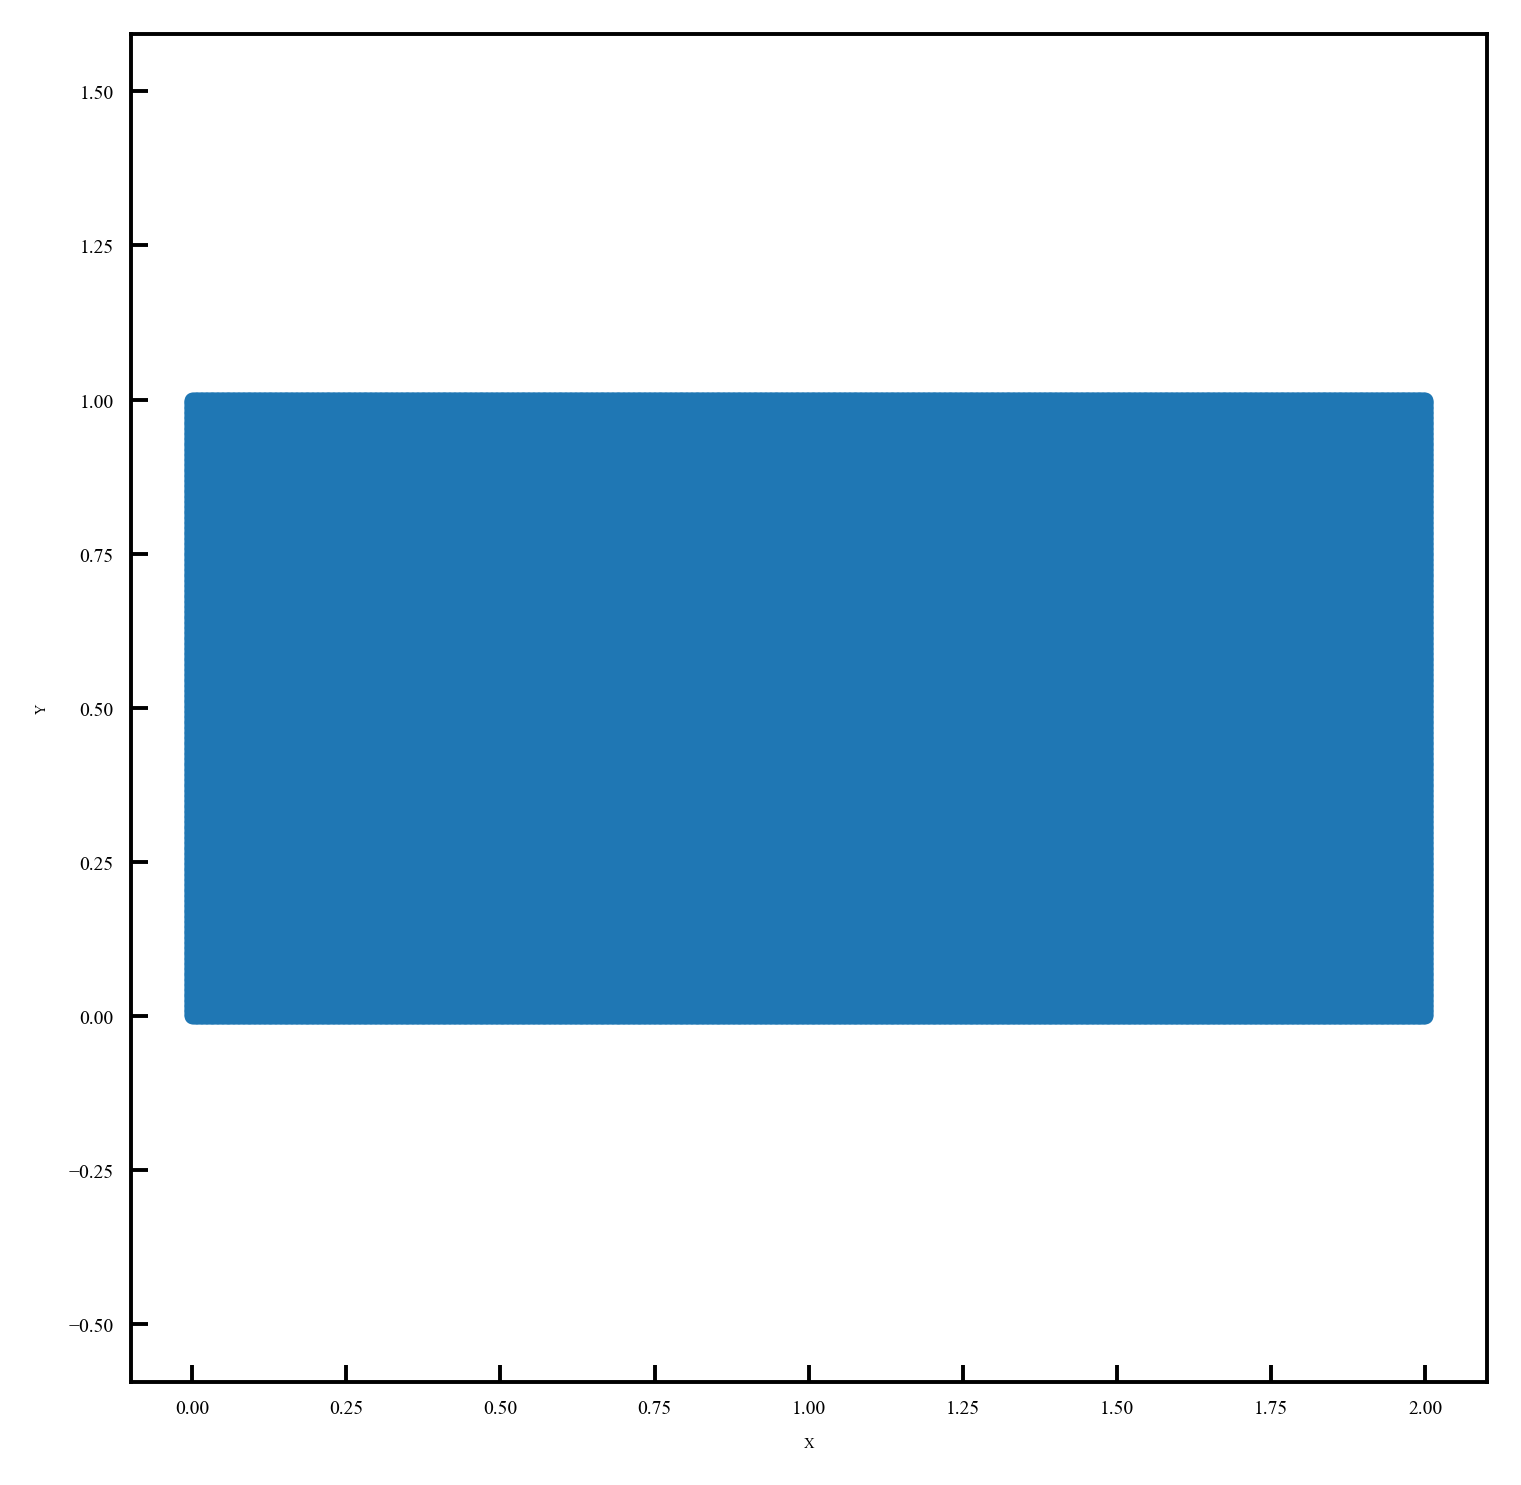

In [6]:
fig = plt.figure(figsize=(5, 5))
ax = fig.add_subplot(111)
ax.scatter(dom[:, 0], dom[:, 1],marker='o', s=5,vmin=0, vmax=1)
ax.set_xlabel('X', fontsize=3)
ax.set_ylabel('Y', fontsize=3)
ax.tick_params(labelsize=4)
plt.axis('equal')
plt.show()

In [7]:
PDNN = PhysicsDrivenNeuralNetwork(layers, 'simpson', 2)

Constructor: Init Network!
Constructor: IntegrationLoss  simpson  in  2  dimension 


In [8]:
start_time = time.time()
PDNN.train_model(dom, dxdy, boundary_neumann, boundary_dirichlet, steps, lr)
end_time = time.time() - start_time
print("End time: %.5f" % end_time)
torch.save(PDNN.model.state_dict(), './output/Case4/model.pt')

Iter_LB: 1 Loss: 2.16966e+01 Internal: 2.66615e+01 Boundary: -4.96489e+00 Time: 2.156e+00
Iter_LB: 101 Loss: 1.34327e+00 Internal: 8.83268e+00 Boundary: -7.48940e+00 Time: 4.923e+01
Iter_LB: 201 Loss: -5.29082e+00 Internal: 3.50840e+00 Boundary: -8.79922e+00 Time: 2.500e+01
Iter_LB: 301 Loss: -7.58248e+00 Internal: 1.98576e+00 Boundary: -9.56823e+00 Time: 2.047e+01
Iter_LB: 401 Loss: -8.64967e+00 Internal: 1.52079e+00 Boundary: -1.01705e+01 Time: 2.042e+01
Iter_LB: 501 Loss: -9.34740e+00 Internal: 1.26737e+00 Boundary: -1.06148e+01 Time: 2.042e+01
Iter_LB: 601 Loss: -9.78398e+00 Internal: 1.03486e+00 Boundary: -1.08188e+01 Time: 2.047e+01
Iter_LB: 701 Loss: -1.00293e+01 Internal: 8.58009e-01 Boundary: -1.08873e+01 Time: 2.038e+01
Iter_LB: 801 Loss: -1.01980e+01 Internal: 7.19257e-01 Boundary: -1.09172e+01 Time: 2.039e+01
Iter_LB: 901 Loss: -1.03032e+01 Internal: 6.12817e-01 Boundary: -1.09160e+01 Time: 2.029e+01
Iter_LB: 1001 Loss: -1.03514e+01 Internal: 5.46788e-01 Boundary: -1.08981e

In [9]:
PDNN.model.load_state_dict(torch.load('./output/Case4/model.pt', map_location=torch.device(dev)))
PDNN.model.eval()

writer_vtk(datatest, './output/Case4/output')